<a href="https://colab.research.google.com/github/kenichiy19/1CCPK-MLAM/blob/main/Global%20Solutions/2026_2/notebooks/02_analises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 – Análises estatísticas
**Global Solution – MLAM | Desafio CitizenTech**

**Problema:** identificar fatores socioeconômicos associados à vulnerabilidade social nos municípios brasileiros, para orientar onde priorizar uma solução de apoio ao cidadão.

**Base utilizada:** `base_municipios_2010.csv`, gerada no notebook `01_preparacao_dados.ipynb` a partir do Atlas do Desenvolvimento Humano no Brasil (PNUD; Ipea; FJP).

**Integrantes:**
- Kenichi Caio Yamamoto – RM 569815
- Rodger Costa Rios – RM 571438

## 1. Preparação do ambiente
Importação das bibliotecas e carregamento da base de dados.

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

In [2]:
base_dados = 'base_municipios_2010.csv'

if not os.path.exists(base_dados):
    from google.colab import files
    files.upload()

base = pd.read_csv(base_dados)
print('Dimensões da base (linhas, colunas):', base.shape)

Dimensões da base (linhas, colunas): (5565, 10)


## 2. Distribuição Normal de Probabilidade
Variável escolhida: **PPOB** (% da população vulnerável à pobreza), por ser a variável central do problema.

Para este item, adota-se a hipótese de que o PPOB segue uma Distribuição Normal. O desvio padrão utilizado é o populacional, pois a base contém todos os municípios brasileiros.

In [3]:
def classificar(probabilidade):
    if probabilidade <= 0.10:
        return 'Raro'
    elif probabilidade < 0.50:
        return 'Pouco provável'
    elif probabilidade <= 0.90:
        return 'Provável'
    else:
        return 'Quase certo'

In [4]:
x = base['PPOB']

media = x.mean()
mediana = x.median()
desvio = x.std(ddof=0)

print(f'Média:         {media:.2f}%')
print(f'Mediana:       {mediana:.2f}%')
print(f'Desvio padrão: {desvio:.2f}')

Média:         43.99%
Mediana:       42.23%
Desvio padrão: 22.44


In [5]:
prob_a = stats.norm.cdf(media, loc=media, scale=desvio)

print(f'Probabilidade de um município ter PPOB menor que a média ({media:.2f}%):')
print(f'{prob_a:.4f} ({prob_a*100:.2f}%)')
print(f'Classificação do evento: {classificar(prob_a)}')

Probabilidade de um município ter PPOB menor que a média (43.99%):
0.5000 (50.00%)
Classificação do evento: Provável


In [6]:
prob_b = stats.norm.sf(mediana, loc=media, scale=desvio)  # sf = 1 - cdf

print(f'Probabilidade de um município ter PPOB maior que a mediana ({mediana:.2f}%):')
print(f'{prob_b:.4f} ({prob_b*100:.2f}%)')
print(f'Classificação do evento: {classificar(prob_b)}')

Probabilidade de um município ter PPOB maior que a mediana (42.23%):
0.5313 (53.13%)
Classificação do evento: Provável


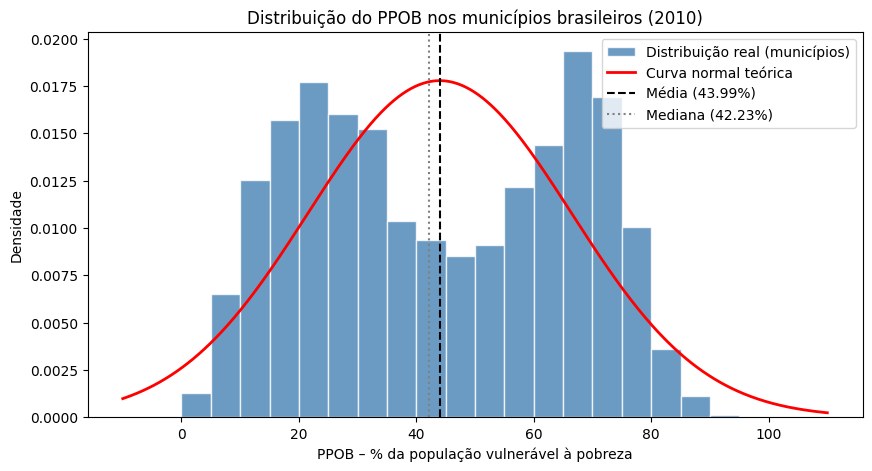

In [7]:
plt.figure(figsize=(10, 5))

plt.hist(x, bins=range(0, 100, 5), density=True, color='steelblue',
         edgecolor='white', alpha=0.8, label='Distribuição real (municípios)')

eixo_x = np.linspace(-10, 110, 500)
plt.plot(eixo_x, stats.norm.pdf(eixo_x, loc=media, scale=desvio),
         color='red', linewidth=2, label='Curva normal teórica')

plt.axvline(media, color='black', linestyle='--', label=f'Média ({media:.2f}%)')
plt.axvline(mediana, color='gray', linestyle=':', label=f'Mediana ({mediana:.2f}%)')

plt.title('Distribuição do PPOB nos municípios brasileiros (2010)')
plt.xlabel('PPOB – % da população vulnerável à pobreza')
plt.ylabel('Densidade')
plt.legend()
plt.show()

### Interpretação dos resultados

Considerando que o percentual da população vulnerável à pobreza (PPOB) segue uma Distribuição Normal, com média de 43,99% e desvio padrão de 22,44 pontos percentuais, foram obtidos os seguintes resultados:

**Probabilidade de o PPOB ser menor que a média:** 50,00%, evento classificado como **provável**. Esse resultado era esperado, pois na Distribuição Normal a média fica exatamente no centro da curva, dividindo os valores em duas partes iguais. Assim, um município escolhido ao acaso tem a mesma chance de estar abaixo ou acima da média nacional de vulnerabilidade.

**Probabilidade de o PPOB ser maior que a mediana:** 53,13%, evento classificado como **provável**. A mediana é o valor que divide os municípios ordenados em duas metades. Na base real, a mediana (42,23%) é um pouco menor que a média (43,99%), reflexo da distribuição dos municípios em dois grupos, de menor e de maior vulnerabilidade. Por isso, o modelo normal estima uma chance ligeiramente superior a 50% de um município estar acima da mediana, embora, nos dados reais, essa proporção seja exatamente 50%.

**Relação com o problema:** em média, quase metade da população dos municípios brasileiros (43,99%) estava em situação de vulnerabilidade à pobreza em 2010, com grande variação entre eles (desvio padrão de 22,44 pontos). Isso reforça a necessidade de priorizar territórios na implantação de uma solução de apoio ao cidadão.

**Limitação:** para os cálculos, adotou-se a hipótese de que o PPOB segue uma Distribuição Normal. No entanto, a distribuição real dos dados não apresenta o formato de sino característico dessa curva: há dois picos, um próximo de 20–25% e outro próximo de 65–70%, o que indica a existência de dois grupos de municípios, um de menor e outro de maior vulnerabilidade. Dessa forma, as probabilidades obtidas devem ser interpretadas como aproximações.

## 3. Testes de hipóteses para a média
Variável escolhida: **PPOB** (% da população vulnerável à pobreza).

Os 5.565 municípios formam a população de referência. Em cada teste, sorteia-se aleatoriamente uma amostra de municípios e compara-se a sua média com a média populacional. Como o desvio padrão populacional é conhecido, utiliza-se o **teste Z**, cuja estatística é:

$$Z = \frac{\bar{x} - \mu}{\sigma / \sqrt{n}}$$

em que $\bar{x}$ é a média da amostra, $\mu$ é a média populacional, $\sigma$ é o desvio padrão populacional e $n$ é o tamanho da amostra. O sorteio usa uma semente fixa (random_state = 42), para que os resultados possam ser reproduzidos.

In [8]:
mu = base['PPOB'].mean()
sigma = base['PPOB'].std(ddof=0)

print(f'Média populacional (μ):          {mu:.2f}%')
print(f'Desvio padrão populacional (σ):  {sigma:.2f}')

Média populacional (μ):          43.99%
Desvio padrão populacional (σ):  22.44


### Teste 1: a média amostral é menor que a média populacional?
- **H₀ (hipótese nula):** a média do PPOB na amostra é igual à média populacional (μ = 43,99%).
- **H₁ (hipótese alternativa):** a média do PPOB na amostra é menor que a média populacional (μ < 43,99%).
- **Nível de significância:** 6% | **Tamanho da amostra:** 20 municípios

In [9]:
n1, alfa1 = 20, 0.06

amostra1 = base.sample(n=n1, random_state=42)['PPOB']
media_amostra1 = amostra1.mean()

z1 = (media_amostra1 - mu) / (sigma / np.sqrt(n1))
z_critico1 = stats.norm.ppf(alfa1)
p_valor1 = stats.norm.cdf(z1)

print(f'Média da amostra:  {media_amostra1:.2f}%')
print(f'Estatística Z:     {z1:.4f}')
print(f'Z crítico:         {z_critico1:.4f}')
print(f'p-valor:           {p_valor1:.4f}')

if z1 < z_critico1:
    print('\nDecisão: rejeita-se H₀. A média da amostra é significativamente menor que a média populacional.')
else:
    print('\nDecisão: não se rejeita H₀. Não há evidência de que a média da amostra seja menor que a média populacional.')

Média da amostra:  43.61%
Estatística Z:     -0.0760
Z crítico:         -1.5548
p-valor:           0.4697

Decisão: não se rejeita H₀. Não há evidência de que a média da amostra seja menor que a média populacional.


### Teste 2: a média amostral é maior que a média populacional?
- **H₀ (hipótese nula):** a média do PPOB na amostra é igual à média populacional (μ = 43,99%).
- **H₁ (hipótese alternativa):** a média do PPOB na amostra é maior que a média populacional (μ > 43,99%).
- **Nível de significância:** 9% | **Tamanho da amostra:** 25 municípios

In [10]:
n2, alfa2 = 25, 0.09

amostra2 = base.sample(n=n2, random_state=42)['PPOB']
media_amostra2 = amostra2.mean()

z2 = (media_amostra2 - mu) / (sigma / np.sqrt(n2))
z_critico2 = stats.norm.ppf(1 - alfa2)
p_valor2 = stats.norm.sf(z2)

print(f'Média da amostra:  {media_amostra2:.2f}%')
print(f'Estatística Z:     {z2:.4f}')
print(f'Z crítico:         {z_critico2:.4f}')
print(f'p-valor:           {p_valor2:.4f}')

if z2 > z_critico2:
    print('\nDecisão: rejeita-se H₀. A média da amostra é significativamente maior que a média populacional.')
else:
    print('\nDecisão: não se rejeita H₀. Não há evidência de que a média da amostra seja maior que a média populacional.')

Média da amostra:  44.13%
Estatística Z:     0.0308
Z crítico:         1.3408
p-valor:           0.4877

Decisão: não se rejeita H₀. Não há evidência de que a média da amostra seja maior que a média populacional.


### Interpretação dos resultados

**Teste 1:** a amostra de 20 municípios apresentou média de 43,61%, valor próximo à média populacional de 43,99%. A estatística Z (−0,08) ficou acima do valor crítico (−1,55), e o p-valor (0,47) é muito superior ao nível de significância de 6%. Assim, não se rejeita a hipótese nula: não há evidência estatística de que a média da amostra seja menor que a média nacional.

**Teste 2:** a amostra de 25 municípios apresentou média de 44,13%, também próxima da média populacional. A estatística Z (0,03) ficou abaixo do valor crítico (1,34), e o p-valor (0,49) é muito superior ao nível de significância de 9%. Assim, não se rejeita a hipótese nula: não há evidência estatística de que a média da amostra seja maior que a média nacional.

O p-valor representa a probabilidade de se obter uma diferença igual ou maior que a observada apenas por acaso. Valores altos, como os encontrados, indicam que as diferenças entre as médias amostrais e a média populacional são compatíveis com a variação natural do sorteio.

**Relação com o problema:** os resultados mostram que pequenas amostras aleatórias de municípios refletem adequadamente o nível médio de vulnerabilidade do país. Isso sugere que levantamentos por amostragem podem ser uma alternativa de menor custo para acompanhar a vulnerabilidade social, desde que os municípios sejam sorteados de forma aleatória.

**Limitação:** os resultados dependem das amostras sorteadas; outras sementes podem gerar médias diferentes. Além disso, o teste Z pressupõe normalidade da média amostral, aproximação que se torna mais confiável com amostras maiores, especialmente porque a distribuição do PPOB não é exatamente normal, como observado anteriormente.

## 4. Análise bivariada
Variáveis analisadas:
- **X (explicativa):** T_ANALF18M – taxa de analfabetismo da população de 18 anos ou mais (%);
- **Y (resposta):** PPOB – % da população vulnerável à pobreza.

Pergunta: municípios com maior analfabetismo tendem a apresentar maior vulnerabilidade à pobreza?

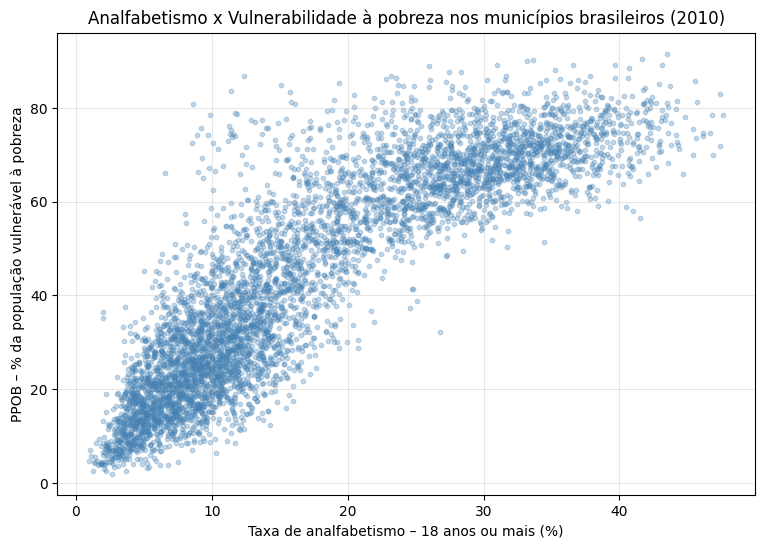

In [11]:
x_biv = base['T_ANALF18M']
y_biv = base['PPOB']

plt.figure(figsize=(9, 6))
plt.scatter(x_biv, y_biv, alpha=0.3, s=10, color='steelblue')
plt.title('Analfabetismo x Vulnerabilidade à pobreza nos municípios brasileiros (2010)')
plt.xlabel('Taxa de analfabetismo – 18 anos ou mais (%)')
plt.ylabel('PPOB – % da população vulnerável à pobreza')
plt.grid(alpha=0.3)
plt.show()

**Interpretação:** cada ponto representa um município. Os pontos formam uma faixa crescente da esquerda para a direita: quanto maior a taxa de analfabetismo, maior tende a ser a proporção da população vulnerável à pobreza. A nuvem de pontos é relativamente concentrada em torno dessa tendência, o que sugere uma relação linear positiva e forte.

In [12]:
covariancia = x_biv.cov(y_biv)
r_pearson, p_pearson = stats.pearsonr(x_biv, y_biv)

print(f'Covariância:                 {covariancia:.2f}')
print(f'Correlação de Pearson (r):   {r_pearson:.4f}')

Covariância:                 210.61
Correlação de Pearson (r):   0.8773


**Interpretação:** a covariância indica a direção da relação entre duas variáveis. O valor positivo (210,61) mostra que analfabetismo e vulnerabilidade variam no mesmo sentido, mas seu valor depende das unidades das variáveis e, por isso, não indica a força da relação.

A correlação de Pearson (r) resolve essa limitação, pois varia de −1 a +1. O valor obtido, **r = 0,88**, indica uma **correlação positiva forte**: municípios com maior analfabetismo tendem, de forma consistente, a apresentar maior vulnerabilidade à pobreza.

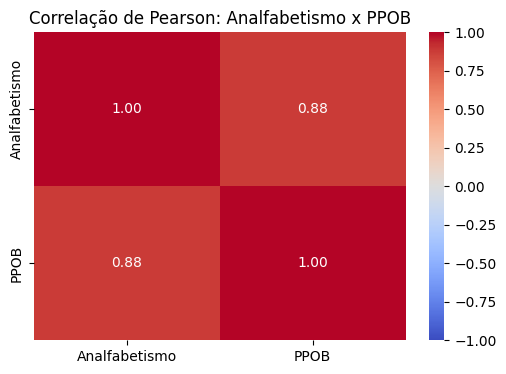

In [13]:
matriz_corr_biv = base[['T_ANALF18M', 'PPOB']].corr(method='pearson')

plt.figure(figsize=(6, 4))
sns.heatmap(matriz_corr_biv, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            xticklabels=['Analfabetismo', 'PPOB'], yticklabels=['Analfabetismo', 'PPOB'])
plt.title('Correlação de Pearson: Analfabetismo x PPOB')
plt.show()

**Interpretação:** o mapa de calor apresenta a correlação entre as variáveis por meio de cores, de azul (correlação negativa) a vermelho (correlação positiva). A diagonal principal vale 1, pois corresponde à correlação de cada variável consigo mesma. Fora da diagonal, o valor de 0,88, em tom avermelhado intenso, confirma a forte correlação positiva entre analfabetismo e vulnerabilidade à pobreza.

In [14]:
X_biv = base[['T_ANALF18M']]

modelo_biv = LinearRegression()
modelo_biv.fit(X_biv, y_biv)

a = modelo_biv.intercept_
b = modelo_biv.coef_[0]
print(f'Equação da regressão: PPOB = {a:.4f} + {b:.4f} × T_ANALF18M')

Equação da regressão: PPOB = 11.9682 + 1.8399 × T_ANALF18M


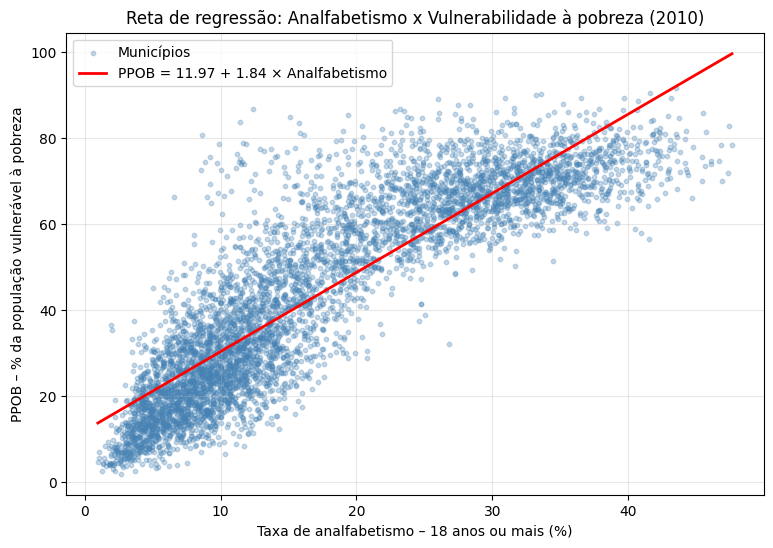

In [15]:
x_reta = pd.DataFrame({'T_ANALF18M': np.linspace(x_biv.min(), x_biv.max(), 100)})

plt.figure(figsize=(9, 6))
plt.scatter(x_biv, y_biv, alpha=0.3, s=10, color='steelblue', label='Municípios')
plt.plot(x_reta['T_ANALF18M'], modelo_biv.predict(x_reta), color='red', linewidth=2,
         label=f'PPOB = {a:.2f} + {b:.2f} × Analfabetismo')
plt.title('Reta de regressão: Analfabetismo x Vulnerabilidade à pobreza (2010)')
plt.xlabel('Taxa de analfabetismo – 18 anos ou mais (%)')
plt.ylabel('PPOB – % da população vulnerável à pobreza')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Interpretação:** a equação obtida foi **PPOB = 11,97 + 1,84 × Analfabetismo**.
- O **coeficiente angular (1,84)** indica que, a cada aumento de 1 ponto percentual na taxa de analfabetismo, o PPOB aumenta, em média, 1,84 ponto percentual.
- O **intercepto (11,97)** representa o PPOB estimado para um município sem analfabetismo. Como nenhum município da base tem taxa zero, esse valor deve ser visto apenas como ponto de partida da reta, sem interpretação prática direta.

In [16]:
y_previsto = modelo_biv.predict(X_biv)
r2_biv = r2_score(y_biv, y_previsto)

n = len(y_biv)   # número de municípios
k = 1            # número de variáveis explicativas
F_biv = (r2_biv / k) / ((1 - r2_biv) / (n - k - 1))
p_F_biv = stats.f.sf(F_biv, k, n - k - 1)

print(f'R²:              {r2_biv:.4f} ({r2_biv*100:.2f}%)')
print(f'Estatística F:   {F_biv:.2f}')
print(f'p-valor do F:    {p_F_biv:.4f}' if p_F_biv >= 0.0001 else 'p-valor do F:    < 0,0001')

R²:              0.7697 (76.97%)
Estatística F:   18588.16
p-valor do F:    < 0,0001


**Interpretação:**
- O **R² (coeficiente de determinação)** foi de **0,7697**, ou seja, cerca de **77% da variação do PPOB entre os municípios é explicada pela taxa de analfabetismo**. Os 23% restantes estão associados a outros fatores não incluídos no modelo.
- O **teste F** verifica se o modelo é estatisticamente significativo, isto é, se a relação encontrada não poderia ter surgido por acaso. A estatística F foi de 18.588,16, com **p-valor inferior a 0,0001**. Como o p-valor é muito menor que o nível de significância usual de 5%, conclui-se que o modelo é **estatisticamente significativo**.

Ressalta-se que essa relação indica **associação, e não causalidade**: o analfabetismo e a vulnerabilidade podem ser influenciados por fatores comuns, como renda e acesso a serviços públicos.

In [17]:
analfabetismo_novo = 20   # município com 20% de adultos analfabetos

ppob_previsto = modelo_biv.predict(pd.DataFrame({'T_ANALF18M': [analfabetismo_novo]}))[0]

print(f'Para um município com {analfabetismo_novo}% de analfabetismo,')
print(f'o PPOB estimado é de {ppob_previsto:.2f}%.')

if ppob_previsto >= 50:
    print('Classificação: município PRIORITÁRIO (PPOB ≥ 50%).')
else:
    print('Classificação: município NÃO prioritário (PPOB < 50%).')

Para um município com 20% de analfabetismo,
o PPOB estimado é de 48.77%.
Classificação: município NÃO prioritário (PPOB < 50%).


**Interpretação:** para um município em que 20% dos adultos são analfabetos (cerca de 1 em cada 5), o modelo estima que **48,77% da população esteja vulnerável à pobreza**, valor muito próximo do limite de 50% adotado para definir um município prioritário.

Pela equação, o PPOB atinge 50% quando a taxa de analfabetismo é de aproximadamente **20,7%**. Assim, municípios com analfabetismo acima desse patamar tendem a ser prioritários. Para uma solução de apoio ao cidadão, isso reforça a importância de recursos acessíveis a pessoas com baixa alfabetização, como orientações por áudio e linguagem simples.

## 5. Regressão linear múltipla
Variáveis analisadas:
- **Y (resposta):** PPOB – % da população vulnerável à pobreza;
- **X₁:** T_ANALF18M – taxa de analfabetismo da população de 18 anos ou mais (%);
- **X₂:** P_FORMAL – grau de formalização do trabalho dos ocupados (%);
- **X₃:** T_BANAGUA – % da população em domicílios com banheiro e água encanada.

Objetivo: verificar se a combinação de fatores educacionais, de trabalho e de infraestrutura explica melhor a vulnerabilidade do que o analfabetismo isoladamente.

In [18]:
explicativas = ['T_ANALF18M', 'P_FORMAL', 'T_BANAGUA']
variaveis_mult = ['PPOB'] + explicativas

nomes = {'PPOB': 'PPOB', 'T_ANALF18M': 'Analfabetismo',
         'P_FORMAL': 'Trabalho formal', 'T_BANAGUA': 'Saneamento'}

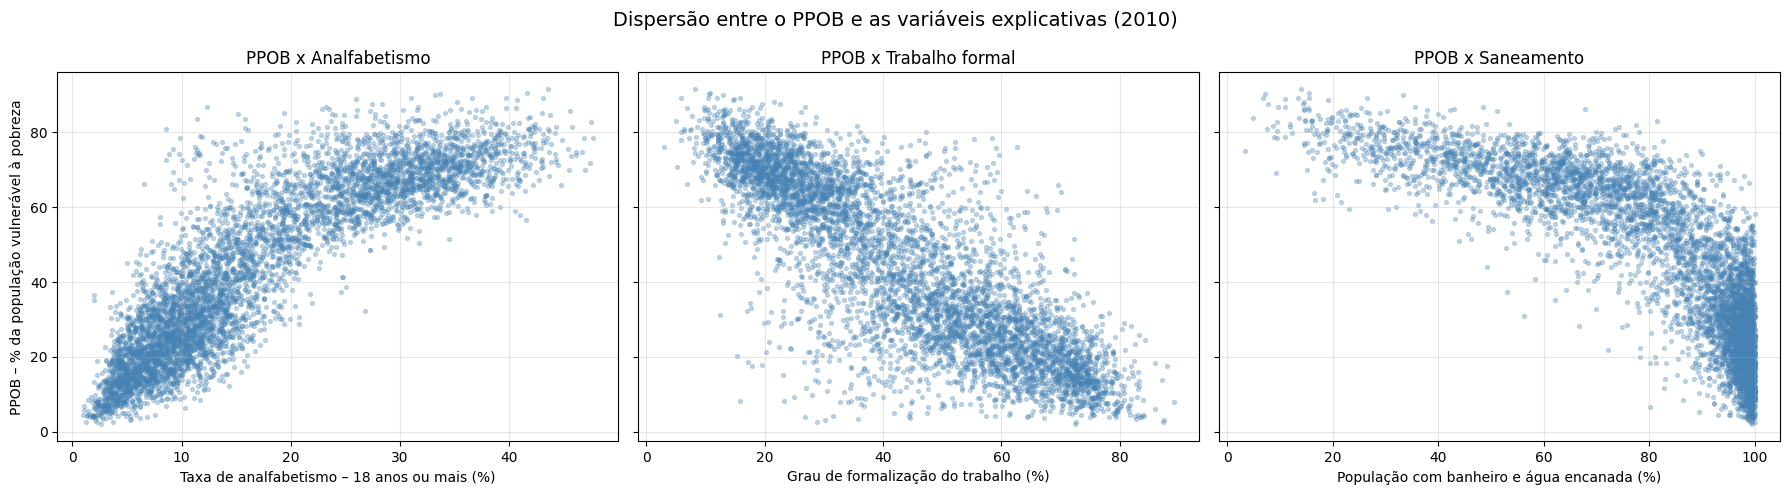

In [19]:
rotulos = {'T_ANALF18M': 'Taxa de analfabetismo – 18 anos ou mais (%)',
           'P_FORMAL':   'Grau de formalização do trabalho (%)',
           'T_BANAGUA':  'População com banheiro e água encanada (%)'}

fig, eixos = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for eixo, variavel in zip(eixos, explicativas):
    eixo.scatter(base[variavel], base['PPOB'], alpha=0.3, s=8, color='steelblue')
    eixo.set_title(f'PPOB x {nomes[variavel]}')
    eixo.set_xlabel(rotulos[variavel])
    eixo.grid(alpha=0.3)

eixos[0].set_ylabel('PPOB – % da população vulnerável à pobreza')
fig.suptitle('Dispersão entre o PPOB e as variáveis explicativas (2010)', fontsize=14)
plt.tight_layout()
plt.show()

**Interpretação:** cada gráfico mostra a relação entre o PPOB e uma das variáveis explicativas, com cada ponto representando um município.
- **Analfabetismo:** os pontos sobem da esquerda para a direita. Quanto maior o analfabetismo, maior tende a ser a vulnerabilidade, uma relação positiva.
- **Trabalho formal:** os pontos descem da esquerda para a direita. Quanto mais trabalho formal, menor tende a ser a vulnerabilidade, uma relação negativa.
- **Saneamento:** os pontos também descem, concentrando-se à direita, já que a maioria dos municípios tem alta cobertura. Os municípios com pior saneamento apresentam, em geral, vulnerabilidade elevada, outra relação negativa.

As três variáveis apresentam relação visível com o PPOB, o que justifica sua inclusão conjunta no modelo de regressão múltipla.

In [20]:
matriz_cov = base[variaveis_mult].cov().rename(index=nomes, columns=nomes)
matriz_cov.round(2)

,PPOB,Analfabetismo,Trabalho formal,Saneamento
PPOB,503.46,210.61,-360.57,-400.17
Analfabetismo,210.61,114.47,-159.12,-173.81
Trabalho formal,-360.57,-159.12,371.53,302.29
Saneamento,-400.17,-173.81,302.29,471.43


In [21]:
matriz_corr = base[variaveis_mult].corr(method='pearson').rename(index=nomes, columns=nomes)
matriz_corr.round(2)

,PPOB,Analfabetismo,Trabalho formal,Saneamento
PPOB,1.00,0.88,-0.83,-0.82
Analfabetismo,0.88,1.00,-0.77,-0.75
Trabalho formal,-0.83,-0.77,1.00,0.72
Saneamento,-0.82,-0.75,0.72,1.00


**Interpretação:** a matriz de covariância indica a direção das relações: valores positivos mostram variáveis que crescem juntas, e negativos, variáveis que variam em sentidos opostos. Como depende das unidades das variáveis, sua magnitude não é comparável.

A matriz de correlação permite comparar a força das relações. Em relação ao PPOB:
- **Analfabetismo:** r = 0,88, correlação positiva forte;
- **Trabalho formal:** r = −0,83, correlação negativa forte;
- **Saneamento:** r = −0,82, correlação negativa forte.

Entre as variáveis explicativas, as correlações também são elevadas (entre 0,72 e 0,77, em valor absoluto), indicando que educação, trabalho e infraestrutura tendem a ocorrer juntos nos municípios. Por isso, os coeficientes da regressão múltipla devem ser interpretados com cautela, pois parte do efeito de cada variável é compartilhada com as demais.

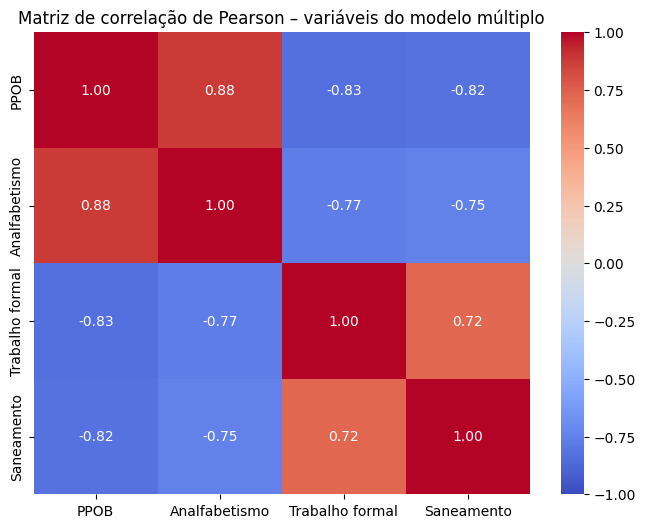

In [22]:
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de correlação de Pearson – variáveis do modelo múltiplo')
plt.show()

**Interpretação:** o mapa de calor destaca em vermelho as correlações positivas e em azul as negativas. A intensidade das cores confirma que todas as variáveis explicativas têm relação forte com o PPOB. Os tons também intensos entre as variáveis explicativas mostram que educação, trabalho e infraestrutura estão interligados nos municípios.

In [23]:
X_mult = base[explicativas]
y_mult = base['PPOB']

modelo_mult = LinearRegression()
modelo_mult.fit(X_mult, y_mult)

a_mult = modelo_mult.intercept_
b1, b2, b3 = modelo_mult.coef_

print('Equação da regressão múltipla:')
print(f'PPOB = {a_mult:.4f} + {b1:.4f} × T_ANALF18M {b2:+.4f} × P_FORMAL {b3:+.4f} × T_BANAGUA')

Equação da regressão múltipla:
PPOB = 65.6673 + 0.9356 × T_ANALF18M -0.3341 × P_FORMAL -0.2897 × T_BANAGUA


**Interpretação:** a equação obtida foi

**PPOB = 65,67 + 0,94 × Analfabetismo − 0,33 × Trabalho formal − 0,29 × Saneamento**

Cada coeficiente indica a variação média do PPOB quando a variável aumenta 1 ponto percentual, **mantidas as demais constantes**:
- **Analfabetismo (+0,94):** aumenta a vulnerabilidade;
- **Trabalho formal (−0,33):** reduz a vulnerabilidade;
- **Saneamento (−0,29):** reduz a vulnerabilidade.

O coeficiente do analfabetismo caiu de 1,84, no modelo simples, para 0,94. Isso ocorre porque, no modelo simples, o analfabetismo também captava parte do efeito do trabalho formal e do saneamento, com os quais está relacionado.

In [24]:
r2_mult = modelo_mult.score(X_mult, y_mult)

n = len(y_mult)
k = len(explicativas)   # 3 variáveis explicativas
F_mult = (r2_mult / k) / ((1 - r2_mult) / (n - k - 1))
p_F_mult = stats.f.sf(F_mult, k, n - k - 1)

print(f'R²:              {r2_mult:.4f} ({r2_mult*100:.2f}%)')
print(f'Estatística F:   {F_mult:.2f}')
print(f'p-valor do F:    {p_F_mult:.4f}' if p_F_mult >= 0.0001 else 'p-valor do F:    < 0,0001')

R²:              0.8609 (86.09%)
Estatística F:   11472.13
p-valor do F:    < 0,0001


**Interpretação:**
- O **R²** foi de **0,8609**: cerca de **86% da variação do PPOB** é explicada pelo conjunto das três variáveis, contra 77% no modelo com apenas o analfabetismo. A inclusão do trabalho formal e do saneamento melhorou o poder explicativo do modelo.
- O **teste F** resultou em F = 11.472,13, com **p-valor inferior a 0,0001**, menor que o nível de significância de 5%. Portanto, o modelo é **estatisticamente significativo**.

Assim como no item anterior, os resultados indicam associação, e não causalidade.

In [25]:
municipio_novo = pd.DataFrame({'T_ANALF18M': [20],
                               'P_FORMAL':   [40],
                               'T_BANAGUA':  [80]})

ppob_previsto_mult = modelo_mult.predict(municipio_novo)[0]

print('Município hipotético: 20% de analfabetismo, 40% de trabalho formal e 80% de saneamento')
print(f'PPOB estimado: {ppob_previsto_mult:.2f}%')

if ppob_previsto_mult >= 50:
    print('Classificação: município PRIORITÁRIO (PPOB ≥ 50%).')
else:
    print('Classificação: município NÃO prioritário (PPOB < 50%).')

Município hipotético: 20% de analfabetismo, 40% de trabalho formal e 80% de saneamento
PPOB estimado: 47.84%
Classificação: município NÃO prioritário (PPOB < 50%).


**Interpretação:** para um município com 20% de analfabetismo, 40% de trabalho formal e 80% da população com banheiro e água encanada, o modelo estima que **47,84% da população esteja vulnerável à pobreza**, valor próximo do limite de 50%.

Para orientar a priorização, isso mostra que municípios com características próximas à média nacional já estão no limite da vulnerabilidade. Uma solução de apoio ao cidadão deve, portanto, considerar não apenas a baixa alfabetização, mas também orientações sobre trabalho formal e acesso a serviços básicos, como saneamento.

## 6. Regressão logística binária
Variáveis analisadas:
- **Y (resposta binária):** PRIORITARIO – 1 se o município tem 50% ou mais da população vulnerável à pobreza; 0 caso contrário;
- **X₁:** T_ANALF18M – taxa de analfabetismo (%);
- **X₂:** P_FORMAL – grau de formalização do trabalho (%);
- **X₃:** T_BANAGUA – % da população com banheiro e água encanada.

A regressão logística estima a **probabilidade** de um município ser prioritário. Quando essa probabilidade é de 50% ou mais, o município é classificado como prioritário.

O PPOB não foi usado como variável explicativa, pois a variável PRIORITARIO foi criada a partir dele.

Para avaliar o modelo em casos novos, os municípios foram divididos em **70% para treino** (ajuste do modelo) e **30% para teste** (avaliação), com semente fixa (random_state = 42). A divisão preserva, nos dois grupos, a mesma proporção de municípios prioritários da base completa.

In [26]:
X_log = base[explicativas]
y_log = base['PRIORITARIO']

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X_log, y_log, test_size=0.30, random_state=42, stratify=y_log)

print('Municípios no treino:', len(X_treino))
print('Municípios no teste: ', len(X_teste))

Municípios no treino: 3895
Municípios no teste:  1670


In [27]:
modelo_log = LogisticRegression(max_iter=1000)
modelo_log.fit(X_treino, y_treino)

b0 = modelo_log.intercept_[0]
b1_log, b2_log, b3_log = modelo_log.coef_[0]

print('Equação da regressão logística:')
print(f'z = {b0:.4f} + {b1_log:.4f} × T_ANALF18M {b2_log:+.4f} × P_FORMAL {b3_log:+.4f} × T_BANAGUA')
print('\nProbabilidade de ser prioritário: P = 1 / (1 + e^(−z))')

Equação da regressão logística:
z = 6.5569 + 0.3593 × T_ANALF18M -0.0506 × P_FORMAL -0.1270 × T_BANAGUA

Probabilidade de ser prioritário: P = 1 / (1 + e^(−z))


**Interpretação:** a regressão logística é composta por duas partes:

1. Uma combinação linear das variáveis, chamada **z**:

   **z = 6,5569 + 0,3593 × Analfabetismo − 0,0506 × Trabalho formal − 0,1270 × Saneamento**

2. A transformação de z em uma probabilidade entre 0 e 1, pela **função logística**:

   $$P(\text{prioritário}) = \frac{1}{1 + e^{-z}}$$

Os sinais dos coeficientes indicam como cada variável afeta a chance de o município ser prioritário, mantidas as demais constantes:
- **Analfabetismo (+):** aumenta a probabilidade de o município ser prioritário;
- **Trabalho formal (−):** reduz essa probabilidade;
- **Saneamento (−):** reduz essa probabilidade.

Os sinais são coerentes com os resultados da regressão linear múltipla.

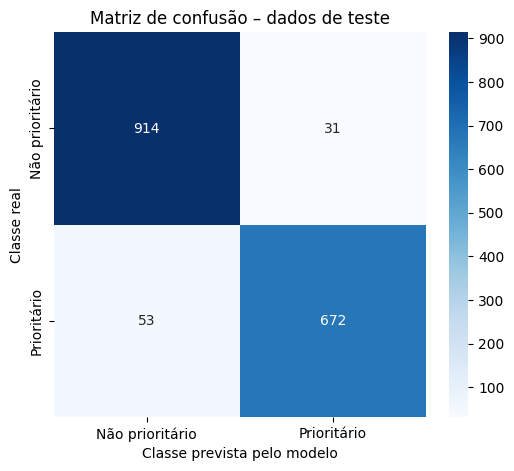

In [28]:
y_previsto_log = modelo_log.predict(X_teste)
matriz_confusao = confusion_matrix(y_teste, y_previsto_log)

plt.figure(figsize=(6, 5))
sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Não prioritário', 'Prioritário'],
            yticklabels=['Não prioritário', 'Prioritário'])
plt.title('Matriz de confusão – dados de teste')
plt.xlabel('Classe prevista pelo modelo')
plt.ylabel('Classe real')
plt.show()

In [29]:
acuracia = accuracy_score(y_teste, y_previsto_log)
referencia = y_teste.value_counts(normalize=True).max()   # acerto de quem "chuta" sempre a classe mais comum

print(f'Acurácia do modelo:             {acuracia:.4f} ({acuracia*100:.2f}%)')
print(f'Acurácia de referência (chute): {referencia:.4f} ({referencia*100:.2f}%)')

Acurácia do modelo:             0.9497 (94.97%)
Acurácia de referência (chute): 0.5659 (56.59%)


**Interpretação:** a matriz de confusão compara a classe real de cada município do teste com a classe prevista pelo modelo:
- **914** municípios não prioritários foram classificados corretamente;
- **672** municípios prioritários foram classificados corretamente;
- **31** municípios não prioritários foram classificados, por engano, como prioritários;
- **53** municípios prioritários foram classificados, por engano, como não prioritários.

A **acurácia**, que é a proporção de classificações corretas, foi de **94,97%** (1.586 acertos em 1.670 municípios). Esse valor é muito superior à acurácia de referência de 56,59%, que seria obtida classificando todos os municípios como não prioritários. Portanto, o modelo tem bom desempenho.

Para o problema, o erro mais grave é o segundo tipo: os **53 municípios prioritários não identificados** deixariam de receber a solução, embora precisem dela. Em uma aplicação real, pode ser preferível aceitar mais alarmes falsos para reduzir esse tipo de erro.

In [30]:
municipio_novo = pd.DataFrame({'T_ANALF18M': [20],
                               'P_FORMAL':   [40],
                               'T_BANAGUA':  [80]})

prob_prioritario = modelo_log.predict_proba(municipio_novo)[0, 1]
classe = modelo_log.predict(municipio_novo)[0]

print('Município hipotético: 20% de analfabetismo, 40% de trabalho formal e 80% de saneamento')
print(f'Probabilidade de ser prioritário: {prob_prioritario:.4f} ({prob_prioritario*100:.2f}%)')
print('Classificação:', 'PRIORITÁRIO' if classe == 1 else 'NÃO prioritário')

Município hipotético: 20% de analfabetismo, 40% de trabalho formal e 80% de saneamento
Probabilidade de ser prioritário: 0.8263 (82.63%)
Classificação: PRIORITÁRIO


**Interpretação:** para o mesmo município hipotético utilizado na regressão linear múltipla (20% de analfabetismo, 40% de trabalho formal e 80% de saneamento), a regressão logística estima uma probabilidade de **82,63%** de ele ser prioritário, classificando-o como **prioritário**.

Esse resultado difere da regressão linear múltipla, que estimou um PPOB de 47,84%, ligeiramente abaixo do limite de 50%, e, portanto, o classificaria como não prioritário. A divergência ocorre porque esse município está muito próximo da fronteira entre os dois grupos, e os modelos funcionam de formas diferentes: a regressão linear estima o valor médio do PPOB, enquanto a regressão logística é ajustada especificamente para separar municípios prioritários e não prioritários.

**Relação com o problema:** em municípios próximos ao limite, a decisão sobre a priorização não deve depender de um único modelo. Recomenda-se que esses casos de fronteira recebam uma análise complementar, considerando dados locais mais recentes, antes da definição de onde implantar a solução de apoio ao cidadão.